We splitsen de auto op per merk en kijken hoeveel mileage de autos hebben en of ze binnen de 30 dagen kapot zijn gegaan of niet om zo per merk een grens te kunnen vaststellen 

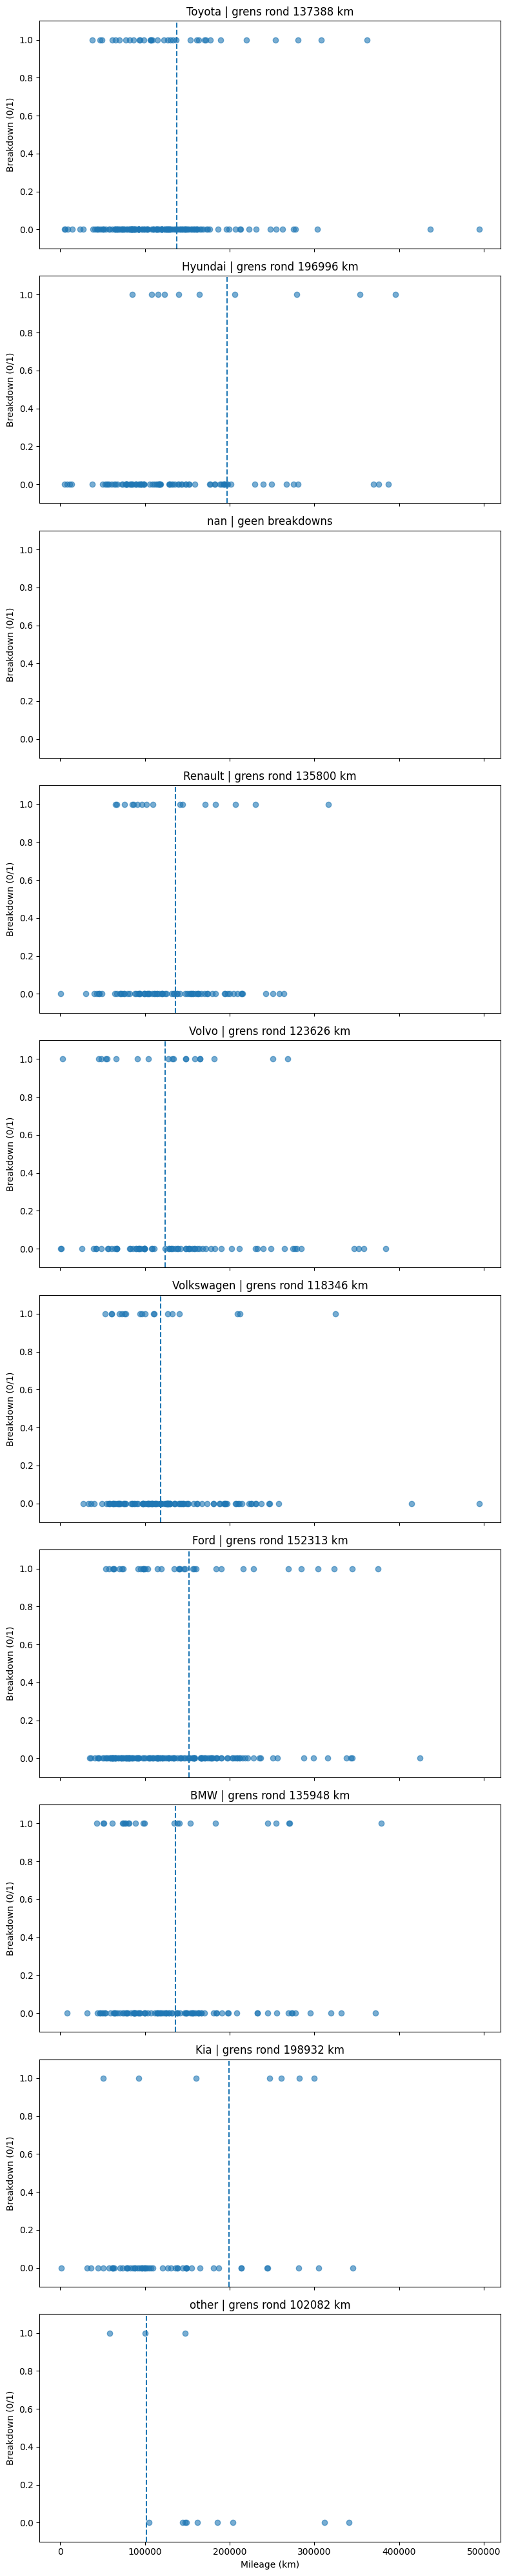

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Lees het bestand in
df = pd.read_csv('../train_CarBreakdown.csv')

# 2. Zorg dat breakdown een integer is
df['breakdown_next_30_days'] = df['breakdown_next_30_days'].astype(int)

# 3. Filtering
df = df[
    (df['mileage_km'].notna()) &
    (df['mileage_km'] > 0) &
    (df['mileage_km'] < 500000) &
    (df['breakdown_next_30_days'].notna())
]

# 4. Unieke merken
brands = df['vehicle_brand'].unique()

fig, axes = plt.subplots(len(brands), 1, figsize=(8, 4 * len(brands)), sharex=True)

if len(brands) == 1:
    axes = [axes]

for ax, brand in zip(axes, brands):

    brand_df = df[df['vehicle_brand'] == brand]

    ax.scatter(
        brand_df['mileage_km'],
        brand_df['breakdown_next_30_days'],
        alpha=0.6
    )

    breakdowns = brand_df[brand_df['breakdown_next_30_days'] == 1]

    if len(breakdowns) > 0:
        threshold = breakdowns['mileage_km'].mean()
        ax.axvline(threshold, linestyle='--')
        ax.set_title(f"{brand} | grens rond {int(threshold)} km")
    else:
        ax.set_title(f"{brand} | geen breakdowns")

    ax.set_ylabel("Breakdown (0/1)")
    ax.set_ylim(-0.1, 1.1)

plt.xlabel("Mileage (km)")
plt.tight_layout()
plt.show()
